# Лабораторная работа 6
## Градиентный бустинг

**Вариант 27**, нечётный: бустинг, не случайный лес.

Модель — сумма деревьев. Каждое следующее учится на остатках предыдущих. Скорость обучения уменьшает вклад нового дерева: маленький шаг требует больше деревьев. Данные — пациенты из лабораторной 4, цель `heart_disease`.


In [1]:
%matplotlib inline
# -*- coding: utf-8 -*-
"""
Лабораторная работа 6 — градиентный бустинг.
Вариант 27 (нечётный).

Данные: heart_disease_dataset.zip из lab4, цель heart_disease.
Запуск: python lab6/lab6.py
Графики: lab6/figures/
"""

from pathlib import Path
import zipfile

import matplotlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import LabelEncoder

ROOT = Path.cwd()
if not (ROOT / 'lab6.py').exists() and (ROOT / 'lab6').is_dir():
    ROOT = ROOT / 'lab6'
DATA_ZIP = ROOT.parent / "lab4" / "heart_disease_dataset.zip"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

RANDOM_STATE = 42
DROP_COLS = [
    "full_name",
    "first_name",
    "last_name",
    "hospital",
    "treatment",
    "treatment_date",
]


def iqr_bounds(series: pd.Series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


def load_heart_frame(zip_path: Path = DATA_ZIP) -> pd.DataFrame:
    with zipfile.ZipFile(zip_path) as zf:
        csv_name = next(name for name in zf.namelist() if name.endswith(".csv"))
        with zf.open(csv_name) as handle:
            return pd.read_csv(handle)


def prepare_features(df: pd.DataFrame):
    """Удаляет идентификаторы, кодирует категории и подрезает выбросы по IQR.

    Масштабирование не делается: разбиения дерева сравнивают порог с исходным
    значением признака, сдвиг и растяжение шкалы на порядок разбиений не влияют.
    """
    frame = df.drop(columns=[c for c in DROP_COLS if c in df.columns]).copy()
    y = frame["heart_disease"].to_numpy()
    X = frame.drop(columns=["heart_disease"])

    cat_cols = X.select_dtypes(include=["object", "str"]).columns.tolist()
    encoder = LabelEncoder()
    for col in cat_cols:
        X[col] = encoder.fit_transform(X[col].astype(str))

    num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    for col in num_cols:
        low, high = iqr_bounds(X[col])
        X[col] = X[col].clip(lower=low, upper=high)

    return X, y, list(X.columns)


def classification_scores(y_true, y_pred, y_prob) -> dict:
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
    }


## 1. Загрузка и подготовка


In [2]:
raw = load_heart_frame()
print("Исходный размер:", raw.shape)
print("Пропусков:", int(raw.isna().sum().sum()))
X_df, y, feature_names = prepare_features(raw)
print("После очистки:", X_df.shape, "классы:", np.bincount(y))

X_train, X_test, y_train, y_test = train_test_split(
    X_df.to_numpy(),
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)
print(f"Train {X_train.shape}, Test {X_test.shape}")


Исходный размер: (10000, 15)
Пропусков: 0
После очистки: (10000, 8) классы: [4993 5007]
Train (8000, 8), Test (2000, 8)


## 2. Базовый градиентный бустинг


  accuracy   0.9380
  precision  0.9320
  recall     0.9451
  f1         0.9385
  roc_auc    0.9825
              precision    recall  f1-score   support

 Нет болезни       0.94      0.93      0.94       999
Есть болезнь       0.93      0.95      0.94      1001

    accuracy                           0.94      2000
   macro avg       0.94      0.94      0.94      2000
weighted avg       0.94      0.94      0.94      2000



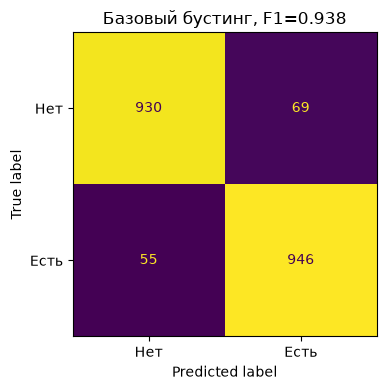

In [3]:
base = GradientBoostingClassifier(random_state=RANDOM_STATE)
base.fit(X_train, y_train)
base_pred = base.predict(X_test)
base_prob = base.predict_proba(X_test)[:, 1]
base_scores = classification_scores(y_test, base_pred, base_prob)
for name, value in base_scores.items():
    print(f"  {name:10s} {value:.4f}")
print(classification_report(y_test, base_pred, target_names=["Нет болезни", "Есть болезнь"]))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    base_pred,
    display_labels=["Нет", "Есть"],
    ax=ax,
    colorbar=False,
)
ax.set_title(f"Базовый бустинг, F1={base_scores['f1']:.3f}")
fig.tight_layout()
fig.savefig(FIG / "01_confusion_base.png", dpi=120, bbox_inches="tight")
plt.show()


## 3. GridSearchCV


Лучшие параметры: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Лучший F1 на CV: 0.9270
Тест после подбора:
  accuracy   0.9385
  precision  0.9329
  recall     0.9451
  f1         0.9390
  roc_auc    0.9837


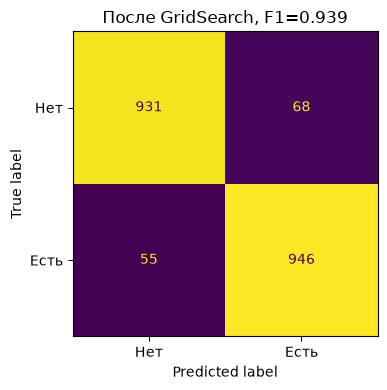

In [4]:
search = GridSearchCV(
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    param_grid={
        "n_estimators": [50, 100, 200],
        "max_depth": [2, 3],
        "learning_rate": [0.05, 0.1],
    },
    scoring="f1",
    cv=3,
    n_jobs=-1,
)
search.fit(X_train, y_train)
print("Лучшие параметры:", search.best_params_)
print(f"Лучший F1 на CV: {search.best_score_:.4f}")

best = search.best_estimator_
best_pred = best.predict(X_test)
best_prob = best.predict_proba(X_test)[:, 1]
best_scores = classification_scores(y_test, best_pred, best_prob)
print("Тест после подбора:")
for name, value in best_scores.items():
    print(f"  {name:10s} {value:.4f}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_pred,
    display_labels=["Нет", "Есть"],
    ax=ax,
    colorbar=False,
)
ax.set_title(f"После GridSearch, F1={best_scores['f1']:.3f}")
fig.tight_layout()
fig.savefig(FIG / "02_confusion_tuned.png", dpi=120, bbox_inches="tight")
plt.show()


## 4. learning_rate и число деревьев


  lr=0.01 trees=20  F1=0.9106


  lr=0.01 trees=50  F1=0.9140


  lr=0.01 trees=100 F1=0.9207


  lr=0.01 trees=200 F1=0.9242


  lr=0.05 trees=20  F1=0.9198


  lr=0.05 trees=50  F1=0.9243


... (6 outputs left out)

  lr=0.3  trees=20  F1=0.9336


  lr=0.3  trees=50  F1=0.9362


  lr=0.3  trees=100 F1=0.9381


  lr=0.3  trees=200 F1=0.9400


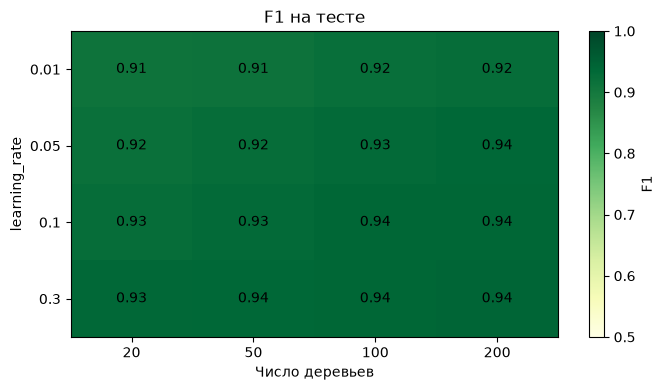

In [5]:
rates = [0.01, 0.05, 0.1, 0.3]
sizes = [20, 50, 100, 200]
heat = np.zeros((len(rates), len(sizes)))
for i, rate in enumerate(rates):
    for j, n_trees in enumerate(sizes):
        model = GradientBoostingClassifier(
            learning_rate=rate,
            n_estimators=n_trees,
            max_depth=3,
            random_state=RANDOM_STATE,
        )
        model.fit(X_train, y_train)
        heat[i, j] = f1_score(y_test, model.predict(X_test), zero_division=0)
        print(f"  lr={rate:<4} trees={n_trees:<3} F1={heat[i, j]:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
image = ax.imshow(heat, cmap="YlGn", vmin=0.5, vmax=1.0, aspect="auto")
ax.set_xticks(range(len(sizes)), [str(n) for n in sizes])
ax.set_yticks(range(len(rates)), [str(r) for r in rates])
ax.set_xlabel("Число деревьев")
ax.set_ylabel("learning_rate")
ax.set_title("F1 на тесте")
for i in range(len(rates)):
    for j in range(len(sizes)):
        ax.text(j, i, f"{heat[i, j]:.2f}", ha="center", va="center")
fig.colorbar(image, ax=ax, label="F1")
fig.tight_layout()
fig.savefig(FIG / "03_lr_vs_trees.png", dpi=120, bbox_inches="tight")
plt.show()


## 5. Важность признаков


Сумма важностей: 1.0
  cholesterol          0.3221
  bmi                  0.2618
  blood_pressure       0.2144
  glucose_level        0.1990
  age                  0.0014
  state                0.0010
  gender               0.0003
  country              0.0000


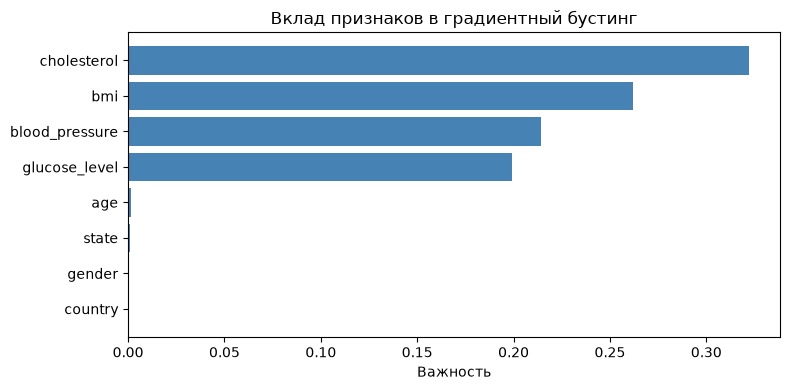


Графики: C:\WORK\MMO\lab6\figures


In [6]:
order = np.argsort(best.feature_importances_)[::-1]
print("Сумма важностей:", float(best.feature_importances_.sum()))
for idx in order:
    print(f"  {feature_names[idx]:20s} {best.feature_importances_[idx]:.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(
    [feature_names[i] for i in order][::-1],
    best.feature_importances_[order][::-1],
    color="steelblue",
)
ax.set_xlabel("Важность")
ax.set_title("Вклад признаков в градиентный бустинг")
fig.tight_layout()
fig.savefig(FIG / "04_feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"\nГрафики: {FIG}")


## Выводы

Базовый бустинг уже даёт F1 около 0.94. Сетка почти не сдвигает тест: удачные параметры и так близки к значениям по умолчанию. При скорости 0.01 нужна длинная сумма деревьев, при 0.1–0.3 качество выходит на полку раньше. Почти вся важность у холестерина, индекса массы тела, давления и глюкозы.
